# 03 · Image module: cat emotion from photos
Supporting component inspired by DeepCat (Cat-Emotional-Analysis). YOLOv8 finds the cat, then a classifier predicts one of four emotions. Data: Cat Emotion Dataset (Hugging Face `KAITANG2003/cat-emotion-dataset`, research use only). Labels in that dataset appear to be model-generated from visual descriptions, so they are noisy; results are treated as indicative only.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from catsense import config as C, data
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40, "display.width", 160)
from IPython.display import Image, display

In [2]:
q = pd.read_csv(C.RESULTS / 'vision_data_quality.csv')
q

,label,images,cat_found_rate,multi_cat_rate
0,Aggressive,707,0.892504,0.031117
1,Happy,1500,0.938000,0.058000
2,Relaxed,1500,0.982667,0.042667
3,Sad,465,0.655914,0.012903


Images where YOLO finds no cat (including non-cat images such as dogs) are removed before training.

In [3]:
vr = pd.read_csv(C.RESULTS / 'vision_results.csv')
vr.round(3)

,model,val_macro_f1,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,train_time_s,predict_ms_per_image
0,baseline (majority),0.139,0.386,0.250,0.097,0.250,0.139,0.215,0.000,0.000
1,logreg_full_image,0.435,0.433,0.417,0.392,0.417,0.399,0.439,8.542,0.008
2,logreg_yolo_crop,0.447,0.457,0.456,0.423,0.456,0.434,0.460,2.912,0.004
3,finetuned_resnet18_crop,0.517,0.542,0.514,0.518,0.514,0.515,0.542,213.841,4.297


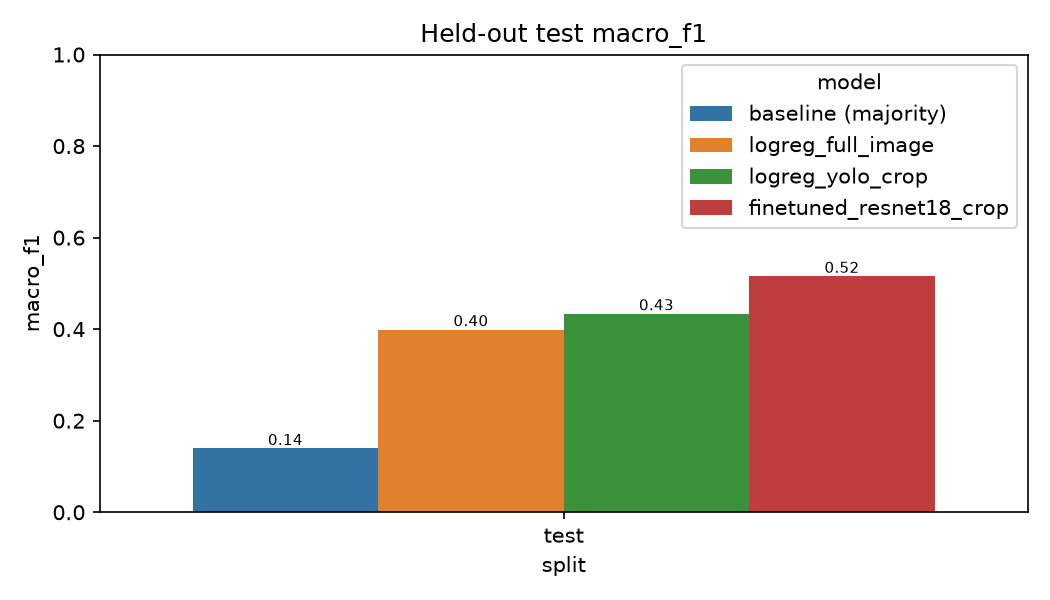

In [4]:
display(Image(C.FIGURES / 'vision_macro_f1.png'))

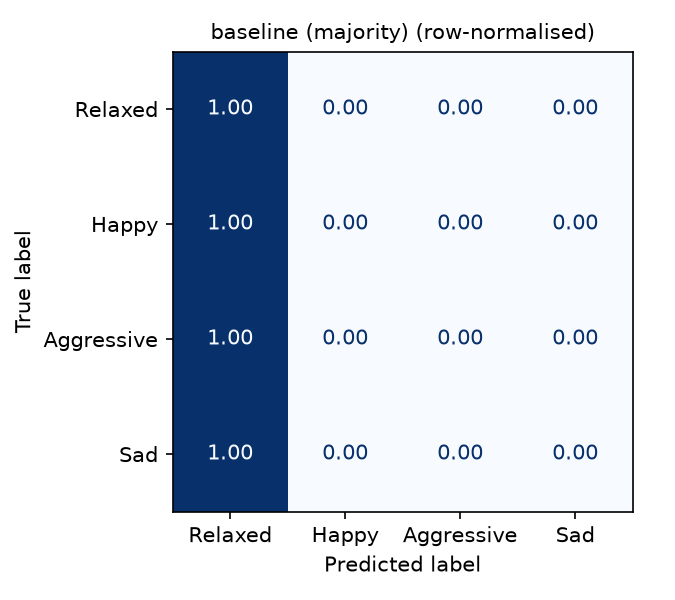

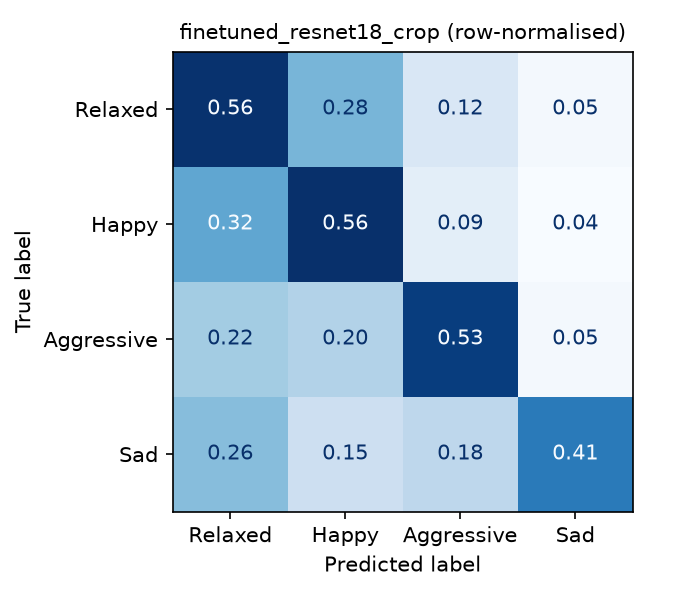

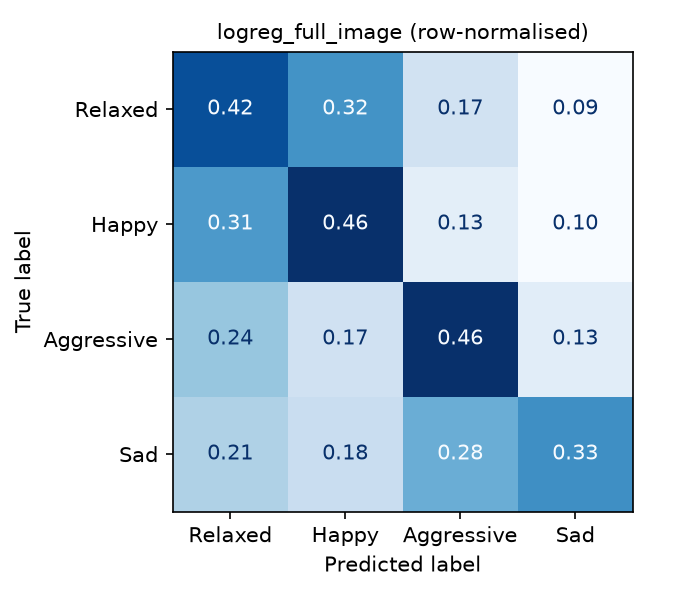

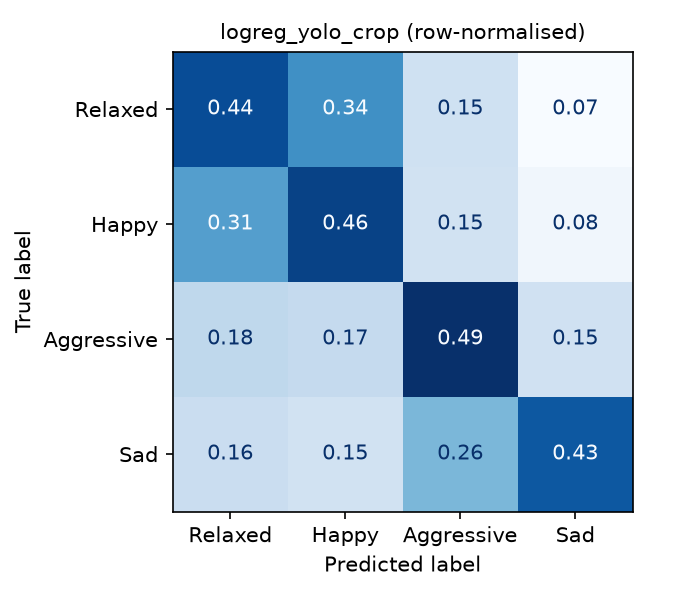

In [5]:
import glob
for f in sorted(glob.glob(str(C.FIGURES / 'cm_vision_*.png'))):
    display(Image(f, width=380))